# MMC v2026 / Colin27: nodal Jacobian audit reference

This is a **completed, offline reference**, not a transport launcher. Run all cells to reconstruct the nodal candidates, check units and ordering, and regenerate the comparisons from retained NPZs. No MMC executable, GPU, neighboring simnirs checkout, or transport cache is required. This temporary notebook can be removed after the findings enter normal project documentation.

## Goal and verdict

Select a practical **fluence-based nodal absorption Jacobian** for the fNIRS forward projection, separating integration, absorption representation, normalization, and detector-model error.

**Current integration choice: keep geometric nodal lumping with one-way normalization. Sassaroli calibration stays off.** This is a deliberate working choice under the remaining modeling uncertainty, not a claim that one-way wins every metric:

\[
J_{ci}=-\frac{v_iG_s(i)G_d(i)}{g_{sd,c}},\qquad v_i=\sum_{e\ni i}V_e/4.
\]

Use MMC v2026 nodal fluences; CUDA is the tested high-statistics backend. The reverse source is the tested inward pencil. This is an approximate nodal estimator, **not an exact captured-detector adjoint or a universal accuracy claim**. Exact P1 product integration improves superficial/systemic RMSE but does not consistently improve cortical predictions. The production equation needs no quadrature change.

The reference measurement is dimensionless captured exit energy per launched source energy, \(M_c=\sum_{p\in c}w_p/N_s\), inside the configured radius-1-mm detector sphere, with no angular/NA filter and a 0–5 ns gate. An embedded reverse pencil does not exactly implement this finite boundary acceptance. Point fluence and captured energy are distinct measurements; a scalar denominator cannot correct a spatial adjoint error.

### Downstream contract: units, shape, and ordering

- Nodal absorption increments \(\theta_i\) are in **mm\(^{-1}\)**. The tested model is \(\mu_{a,e}=\mu_{a0,e}+\tfrac14\sum_{i\in e}\theta_i\): centroid-averaged **increments**, keeping the sharp heterogeneous baseline. Continuous P1 absorption is a different model.
- The integrated J is in **mm**: \(\Delta\ln M=J\theta\). Natural-log OD is \(-J\theta\); decadic OD is \(-J\theta/\ln10\). The simulator's decadic extinction conversion includes \(\ln(10)/10\) for mm-based natural absorption.
- **Volume is already in J.** Plotted density \(-J_i/v_i\) has units mm\(^{-2}\); it is only a visualization, not the downstream array.
- Production files use \(J=(N_sN_d,N_{\rm nodes})\), row \(sN_d+d\), and \(\mathrm{mea0}=(N_sN_d,1)\): here **(216, 58,686)** and **(216, 1)**. The channelidx array selects 36 measured pairs; simnirs uses **(wavelength, node, channel)**.
- Audit arrays contain only measured rows in original probe order: **(36, 58,686)** per method. **nodal_candidates_850nm_1e9.npz** stores **Q[3,36,58686]**, not an interchangeable production file. Divide Q by its saved channel denominator to obtain J. Explicit pairs, channel_indices \(=s*27+d\), and node_indices define ordering.
- Cleanup corrected an **audit-only metadata bug**: 13 channel_indices had been copied from a sorted QC list instead of the unsorted probe pairs. No matrix values or method comparisons changed. Production all-pair indexing was unaffected.

### Versions and formulations examined

Software versions inspected were **v2025.10 and tagged v2026**. The reproducible numerical comparisons below use v2026; they do not establish quantitative equivalence between releases.

| Explicit dataset | Calculation | Available evidence |
|---|---|---|
| v2026, 850 nm, \(10^8\) photons per emitter | Nodal and element fluence, three seeds on one measured pair, native full FEM | Complete numerators, normalizers, captured-history summaries, repeat variability and native own-field checks |
| v2026 revision **8bf9ef**, CUDA, 850 nm, \(10^9\) per emitter | Shared 8 source + 27 reverse fields, nodal and element output; ten \(10^8\) chunks | 36 measured rows, mean nodal fields, complete candidates, element replay reference, fixed-test uncertainty and finite checks |
| Post-processing of these fields | Lumped, FEM-quarter, P1; one-way/symmetric denominators; Sassaroli | No extra transport; spatial construction and scalar normalization are evaluated separately |

The \(10^8\) datasets used roulette and the \(10^9\) datasets disabled it; their difference is not purely photon-count convergence. Native raw jmua stays an absolute/bilinear quantity. Own-field formula agreement does not establish a captured-energy log derivative.

### What the reported “errors” mean

The reference estimates the derivative of the **configured MMC measurement**, not the response of a real head. For fixed geometry, scattering, refractive indices and detector acceptance, detected-photon weighted pathlength gives
\[
\widehat J^{\rm ref}_{ce}=-\frac{\sum_{p\in c}w_pL_{pe}}{\sum_{p\in c}w_p}.
\]
This is a Monte Carlo estimate of a well-defined captured-energy log derivative for element absorption. For the tested centroid-nodal increment model, \(J^{\rm ref}_n=\widehat J^{\rm ref}_eP\). It is not the exact derivative for continuously varying P1 absorption.

For nodal spatial pattern \(b_f\), the tabulated response discrepancy is
\[
E_{cf}=a\big[(J^{\rm candidate}-J^{\rm ref}_n)b_f\big]_c,
\qquad a=0.001\ {\rm mm}^{-1}.
\]
RMSE is the root mean square of these differences in predicted \(\Delta\ln M\). Median absolute relative error is the median of \(|E_{cf}/(a[J^{\rm ref}_n b_f]_c)|\), reported only for sufficiently supported, non-negligible reference responses. It is not a percentage difference between plotted Jacobian densities.

**We do not have experimental ground truth or an exact noise-free spatial Jacobian.** Replay is a statistically uncertain, measurement-matched model reference. Paired chunk analysis accounts for shared Monte Carlo samples; independent finite perturbation checks cover only specific element-defined fields. They do not validate every nodal field, a continuous-P1 model, or the real detector/head. Differences also include the fluence-product/adjoint approximation, not just quadrature error.

Small absolute RMSE numbers partly reflect the small chosen absorption amplitude; they scale with that amplitude. Typical cortical discrepancies of roughly 10–12% remain meaningful within the assumed model. The differences between normalization choices are modest, but no instrument-noise or application-tolerance test establishes that all physical errors are small.

### Numerical comparisons against the model reference

**Population: only the 36 selected/measured probe pairs, not all 216 possible source–detector combinations.** The table uses supported channel–perturbation cases within that population. Detailed all-case absolute metrics include every measured channel and weak-reference case.

RMSE of \(\Delta\ln M\) at nodal amplitude \(0.001\) mm\(^{-1}\), on supported matched-reference cases:

| Construction / denominator | Cortical RMSE | Scalp RMSE | Spatial physiology RMSE |
|---|---:|---:|---:|
| **Lumped / one-way** | **0.000112** | 0.002543 | 0.003201 |
| Lumped / symmetric | 0.000128 | 0.002287 | 0.003098 |
| Lumped / calibrated (diagnostic) | 0.000115 | 0.002276 | 0.002967 |
| FEM-quarter / one-way | 0.000125 | 0.002586 | 0.002703 |
| Exact P1 / one-way | 0.000118 | 0.002477 | 0.002584 |
| Exact P1 / symmetric | 0.000127 | **0.001983** | **0.002210** |

One-way cortical median absolute errors are **12.5%, 37.4%, and 32.4%** for lumped, FEM-quarter, and P1. Strong responses dominate RMSE, so its ranking differs from the median across locations. Median relative spatial sampling SE is about 0.07–0.08% for one-way estimates; fluence variance does not explain the main discrepancies.

Coverage: **78/864 cortical, 51/216 scalp, and 41/108 spatial-physiology cases** meet ESS ≥2000, reference relative SE ≤5%, and response magnitude ≥0.01 mm. All weak cases remain visible. Ten chunks quantify one pooled \(10^9\) estimate, not ten independent full-budget repeats.

FEM-quarter and P1 have identical totals but different distributions. Native full FEM matches its own-field quarter assembly (relative residual <\(6\times10^{-7}\)); this checks implementation, not physical accuracy. Sassaroli forces the total pathlength and makes calibrated one-way/symmetric variants identical for a fixed Q. Calibration gives the lowest observed median discrepancies for lumping in the cortical/scalp/physiology tests (10.89% / 8.43% / 6.12%), but does not improve every absolute-error metric or every construction. Those localized gains are not forced by total matching. Calibration remains a downstream diagnostic and is not enabled.

### Why keep one-way for now?

They use **exactly the same spatial numerator**. Symmetric normalization multiplies each channel row by \(2g_{sd}/(g_{sd}+g_{ds})\); the median absolute row change is **4.8%** (range of multipliers: **0.823–1.132**). Neither denominator has been proven to convert the reverse-pencil field into the exact captured-detector derivative.

For lumping, switching to symmetric changes cortical RMSE from \(1.116\times10^{-4}\) to \(1.276\times10^{-4}\) in \(\Delta\ln M\): an absolute increase of **\(1.60\times10^{-5}\)**, or 14.3%. Scalp RMSE improves 10.1% and physiology RMSE improves 3.2%. Median cortical percentage error also improves, **12.46% → 11.19%**. Thus one-way wins the signal-weighted cortical RMSE metric, while symmetric wins several others.

The cortical RMSE difference has a paired Monte Carlo 95% interval of **\([1.52,1.67]\times10^{-5}\)**. It is resolved relative to sampling noise, but its practical importance is not established by that interval: detector-model error and limited spatial reference coverage remain. **There is no strong general scientific case to reject symmetric normalization.** The chosen integration setting remains one-way; symmetric and calibrated views remain comparison diagnostics. A different application objective could favor them. This choice does not turn the reference discrepancy into a known physical error or settle the detector-model question.

The detector-matched reference differentiates element-supported captured energy. For nodal centroid increments it becomes \(J_e^{\rm replay}P\). This is a diagnostic reference, not the proposed production nodal estimator. No exact continuous-P1 path reference or universal finite-amplitude validity is claimed.

### Retained files and reproduction

The **jacobian_audit/** directory contains canonical NPZs and one **comparison/** folder. Mean nodal fluences reproduce the three complete numerators; saved delete-one projections reproduce the tested uncertainties. Raw histories and individual chunk fields are not required for this fixed analysis and are not retained. New arbitrary-field replay uncertainty would need regeneration; saved full Jacobians still support new deterministic projections.

Cells below reproduce cached analysis without changing transport results. The general QC notebook is untouched. All three end-to-end workflows call the unchanged nodal one-way generator and use its uncalibrated J. The saved pathlength ratio is diagnostic only. They offer HF-manifest refresh and backend selection: CUDA defaults when the NVIDIA driver finds a device; otherwise OpenCL, with CPU (sse) available. New generation follows the manifest's declared version and uses a 300-second timeout. Loading an existing Jacobian does not upgrade it.

In [1]:
# 1. Load retained, portable audit data. No transport or runtime discovery.
from pathlib import Path
from types import SimpleNamespace
import csv, hashlib, json, math
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"pyproject.toml").exists())
RESULTS=ROOT/"notebooks/jacobian_audit";COMPARE=RESULTS/"comparison"
COMPARE.mkdir(exist_ok=True)
def load_npz(path):
    with np.load(path,allow_pickle=False) as z: return {k:z[k] for k in z.files}
def metadata(bundle): return json.loads(str(bundle["metadata_json"]))
def sha(path):
    with Path(path).open("rb") as f: return hashlib.file_digest(f,"sha256").hexdigest()
def table(name,rows):
    if rows:
        with (COMPARE/name).open("w",newline="") as f:
            w=csv.DictWriter(f,fieldnames=list(dict.fromkeys(k for r in rows for k in r)))
            w.writeheader();w.writerows(rows)
def save_json(path,data):
    Path(path).write_text(json.dumps(data,indent=2,default=lambda x:np.asarray(x).tolist())+"\n")
def jackknife(a,axis=0):
    return np.sqrt((a.shape[axis]-1)/a.shape[axis]*np.sum((a-a.mean(axis,keepdims=True))**2,axis=axis))
basis=load_npz(RESULTS/"colin27_basis.npz")
nodes,elem,types=(basis[k] for k in ("nodes","elements","tissue_ids"))
vol,v=(basis[k] for k in ("element_volumes_mm3","node_volumes_mm3"))
B,Bn,props,pairs=(basis[k] for k in ("B","B_nodes","optical_properties","pairs"))
names=basis["mode_names"].tolist();input_id=metadata(basis)["input_id"]
F=sparse.coo_matrix((np.repeat(vol/4,4)/v[elem.ravel()],(elem.ravel(),np.repeat(np.arange(len(elem)),4))),
                   shape=(len(nodes),len(elem))).tocsr()
P=sparse.coo_matrix((np.full(elem.size,.25),(np.repeat(np.arange(len(elem)),4),elem.ravel())),
                   shape=(len(elem),len(nodes))).tocsr()
datasets={}
for kind in ("nodal","element"):
    for budget in ("1e8","1e9"):
        a=load_npz(RESULTS/f"{kind}_850nm_{budget}.npz");datasets[kind,budget]=(a,metadata(a))
nc=load_npz(RESULTS/"nodal_candidates_850nm_1e9.npz");nmeta=metadata(nc)
means=load_npz(RESULTS/"nodal_fluence_means_850nm_1e9.npz")
spatial_reference=load_npz(RESULTS/"spatial_replay_850nm_1e9.npz")
rep=load_npz(RESULTS/"audited_pair_850nm_1e8_repeats.npz")
nodal_base=datasets["nodal","1e9"][0];nodal_replay=spatial_reference
inputs=SimpleNamespace(**{k:means[k] for k in ("source_positions","detector_positions","source_directions",
    "detector_directions","source_elements","detector_elements")})
nodal_methods=tuple(nmeta["methods"]);nodal_norms=("oneway","symmetric","calibrated")
nodal_specs=nmeta["fields"];Nfields=nc["fields_nodes"];Efields=P@Nfields
gaussian_specs=metadata(spatial_reference)["gaussian_fields"]
centroids=nodes[elem].mean(1)
G=np.column_stack([np.exp(-np.sum((centroids-g["center_mm"])**2,axis=1)/(2*g["sigma_mm"]**2))*(types==g["tissue"]) for g in gaussian_specs])
midpoints=(inputs.source_positions[pairs[:,0]]+inputs.detector_positions[pairs[:,1]])/2
narrow_sigma=min(g["sigma_mm"] for g in gaussian_specs)
REFERENCE_CHANNELS=basis["reference_channels"].astype(int).tolist()
short_channel,long_channel=REFERENCE_CHANNELS
C,NN,T=len(pairs),len(nodes),Nfields.shape[1];K=nc["Q_response_loo"].shape[1]
r=spatial_reference
supported=(r["ESS"][:,None]>=2000)&(r["gaussian_SE_mm"]<=.05*abs(r["gaussian_response_mm"]))&(abs(r["gaussian_response_mm"])>=.01)
for a in (nc,r,means,*[a for a,m in datasets.values()]):
    np.testing.assert_array_equal(a["pairs"],pairs)
for a in (nc,r):
    np.testing.assert_array_equal(a["channel_indices"],pairs[:,0]*len(means["detector_ids"])+pairs[:,1])
np.testing.assert_array_equal(nc["node_indices"],np.arange(NN))
np.testing.assert_array_equal(r["element_indices"],np.arange(len(elem)))
assert nc["Q"].shape==(3,36,58686) and r["J_log_elements"].shape==(36,330983) and K==10
np.testing.assert_allclose(nc["Q_response"],nc["Q"]@Nfields,rtol=2e-12,atol=1e-15)
np.testing.assert_allclose(nc["reference_response"],r["J_log_elements"]@Efields,rtol=2e-12,atol=1e-14)
print("Loaded 36 measured channels, 58,686 nodes, 330,983 elements; saved row identities verified.")


Loaded 36 measured channels, 58,686 nodes, 330,983 elements; saved row identities verified.


## Reproduction: physical model and numerical checks

Lengths are mm; optical columns are \((\mu_a,\mu_s,g,n)\), with reduced scattering \(\mu_s'=\mu_s(1-g)\). Geometry and property identities are recorded in the bundles. Sources and detector centers are contained in their assigned tetrahedra and point inward. Original depth/boundary checks and build/seed records remain in **comparison/input_checks.json** and **cleanup_provenance.json**.

In simnirs, cortical element masks become nodal fractions through \(F_{ie}=V_e/(4v_i)\). Spatial physiology multiplies nodal tissue weights by smooth nodal modes. Hemoglobin changes become nodal absorption increments and are projected with J. This algebra does not uniquely specify a continuous interpolation. The comparison explicitly uses **centroid-averaged increments** \(P\theta\), with \(P_{ei}=1/4\) at incident nodes.

\(P\ne F^{-1}\). Nodal fractions mix interfaces, so \(PFB\) differs from binary region \(B\). Setting absolute MMC nodemua to \(F\mu_0\) would also blur baseline optics; that is not a matched independent validation.

| Candidate | Nodal numerator Q | Interpretation |
|---|---|---|
| Lumped | \(-v_i a_i b_i\) | Geometric vertex quadrature; current production estimator |
| FEM quarter | \(P^\top[-V_e((\sum a)(\sum b)+a\cdot b)/20]\) | Exact two-P1-field integration for centroid-constant increments; tagged native full-FEM assembly |
| P1 exact | \(-\sum_{e\ni i}\int_{\Omega_e}N_iab\,dV\) | Degree-three integration for continuous P1 absorption; tested here only as an approximate centroid-model estimator |

Replay is \(-\sum_p w_pL_{pe}/\sum_p w_p\), in mm. Multiplication by P gives the centroid-nodal reference, **not** an exact continuous-P1 reference. Native raw jmua has integrated volume and stays separate from log sensitivity. Native nodal approximation additionally uses a boundary-corrected nodal volume; production geometric lumping does not.

One-way \(Q/g_{sd}\) and symmetric \(2Q/(g_{sd}+g_{ds})\) differ only by channel scale. This is a [Cedalion-style](https://github.com/ibs-lab/cedalion/blob/main/src/cedalion/dot/forward_model.py) denominator, not a reproduction of MCX voxels, optodes or surface projection. Sassaroli uses a fixed baseline \(\beta=L^{det}/(-\sum_iJ_i)\); equivalent calibrated denominators are shown once.

[MMC issue #134](https://github.com/fangq/mmc/issues/134) explains why reverse emission and detector reception matter. Neither point isotropic emission nor flat-boundary scaling establishes the correct curved Colin27 aperture. The retained small profile pilot was inconclusive; no alternative full-montage detector model is claimed.


In [2]:
# 2. Geometry, integration, and complete mean-field reconstruction.
tet=nodes[elem]
volume_check=abs(np.einsum("ij,ij->i",tet[:,1]-tet[:,0],np.cross(tet[:,2]-tet[:,0],tet[:,3]-tet[:,0])))/6
np.testing.assert_allclose(volume_check,vol,rtol=2e-12)
np.testing.assert_allclose(np.bincount(elem.ravel(),weights=np.repeat(vol/4,4),minlength=NN),v,rtol=2e-12)
np.testing.assert_allclose(F@B,Bn,rtol=2e-12,atol=1e-15)
np.testing.assert_allclose(np.asarray(F.sum(1)).ravel(),1)
assert np.all(vol>0) and np.all(v>0) and props.shape==(6,4)
for role in ("source","detector"):
    for pos,direction,e in zip(means[role+"_positions"],means[role+"_directions"],means[role+"_elements"]):
        t=nodes[elem[e]];u=np.linalg.solve((t[1:]-t[0]).T,pos-t[0])
        assert min(np.r_[1-u.sum(),u])>-1e-5
        np.testing.assert_allclose(np.linalg.norm(direction),1,rtol=1e-6)
moment=np.empty((4,4,4))
for i in range(4):
    for j in range(4):
        for k in range(4):
            moment[i,j,k]=math.prod(math.factorial(m) for m in np.bincount([i,j,k],minlength=4))/120
def fem(a,b):
    x,y=a[elem],b[elem]
    return -vol*(x.sum(1)*y.sum(1)+(x*y).sum(1))/20
def p1(a,b):
    local=-vol[:,None]*np.einsum("ijk,ej,ek->ei",moment,a[elem],b[elem])
    return np.bincount(elem.ravel(),weights=local.ravel(),minlength=NN)
def nodal_q(a,b): return np.stack([-v*a*b,np.asarray(P.T@fem(a,b)),p1(a,b)])
def point_value(field,pos,e):
    t=nodes[elem[e]];u=np.linalg.solve((t[1:]-t[0]).T,pos-t[0])
    return np.r_[1-u.sum(),u]@field[elem[e]]
np.testing.assert_allclose(moment.sum(0),(np.ones((4,4))+np.eye(4))/20,rtol=1e-14)
np.testing.assert_allclose(moment.sum((1,2)),np.ones(4)/4,rtol=1e-14)
a=np.array([1.,2.,4.,8.]);b=np.array([3.,1.,5.,2.])
np.testing.assert_allclose(np.einsum("ijk,j,k->i",moment,a,np.ones(4)),(a.sum()+a)/20)
exact=np.einsum("ijk,j,k->i",moment,a,b)
np.testing.assert_allclose(exact,[2.233333333333333,2.058333333333333,3.041666666666667,2.966666666666667])
assert not np.allclose(exact,exact.sum()/4)
np.testing.assert_allclose(nodal_q(np.ones(NN),np.ones(NN)),np.tile(-v,(3,1)),rtol=2e-12)
source_fields=dict(zip(means["source_ids"],means["source_fields"]))
detector_fields=dict(zip(means["detector_ids"],means["detector_fields"]))
for c,(s,d) in enumerate(pairs):
    a,b=source_fields[s],detector_fields[d]
    np.testing.assert_allclose(nodal_q(a,b),nc["Q"][:,c],rtol=2e-12,atol=1e-20)
    np.testing.assert_allclose(fem(a,b),nodal_base["Q_fem"][c],rtol=2e-12,atol=1e-20)
    np.testing.assert_allclose(point_value(a,inputs.detector_positions[d],inputs.detector_elements[d]),nc["g_sd"][c],rtol=2e-12)
    np.testing.assert_allclose(point_value(b,inputs.source_positions[s],inputs.source_elements[s]),nc["g_ds"][c],rtol=2e-12)
np.testing.assert_allclose(nc["Q"].sum(2)[1],nc["Q"].sum(2)[2],rtol=2e-12)
np.testing.assert_allclose(nc["M"],nodal_replay["M"],rtol=2e-12)
np.testing.assert_allclose(-nodal_replay["J_log_elements"].sum(1),nc["L_total"],rtol=.003)
assert np.all(nc["Q"]<=0)
print("All three nodal reconstructions, denominators, analytical identities and captured totals verified.")


All three nodal reconstructions, denominators, analytical identities and captured totals verified.


## Matched response comparisons

The 41 retained nodal fields include anatomy-selected GM/scalp Gaussians, spatial physiology, uniform controls, and supplementary motor masks. Every candidate sees the same nodal values; the reference sees P times those values. Percentages are reported only for sufficiently supported responses. Absolute errors and coverage retain every measured row. Paired delete-one uncertainty keeps correlations between methods sharing the same fields.

In [3]:
# 3. Matched nodal comparisons; raw Q, denominators, and fixed baseline calibration.
# Matched reference and numerator/denominator/calibration decomposition.
nr=nc["reference_response"];nrloo=nc["reference_loo"];nrse=jackknife(nrloo)
nsupported=(nc["ESS"][:,None]>=2000)&(nrse<=.05*np.abs(nr))&(np.abs(nr)>=.01)
nq=nc["Q"];nqh=nc["Q_response"];nqt=nq.sum(2)
ng=np.stack([nc["g_sd"],(nc["g_sd"]+nc["g_ds"])/2])
nbeta=-nc["L_total"][None,:]/(nqt/ng[0])
nviews=np.stack([nqh/ng[0][None,:,None],nqh/ng[1][None,:,None],nqh*(-nc["L_total"][None,:]/nqt)[:,:,None]],axis=1)
nlooviews=np.stack([nc["Q_response_loo"]/nc["g_loo"][0][None,:,:,None],
    nc["Q_response_loo"]/nc["g_loo"][1][None,:,:,None],
    nc["Q_response_loo"]*(-nodal_base["loo_reference_total"][None,:,:]/nc["Q_total_loo"])[:,:,:,None]],axis=1)
for m in range(3):
    j1=nq[m]/ng[0,:,None];js=nq[m]/ng[1,:,None]
    np.testing.assert_allclose(js,j1*(2*nc["g_sd"]/(nc["g_sd"]+nc["g_ds"]))[:,None],rtol=2e-14,atol=1e-20)
    np.testing.assert_allclose(j1*nbeta[m,:,None],js*(-nc["L_total"]/(nqt[m]/ng[1]))[:,None],rtol=2e-14,atol=1e-20)
groups=np.asarray([g["group"] for g in nodal_specs]);amplitude=.001
nodal_metrics=[];nodal_rows=[];nodal_pairwise=[];nodal_uncertainty=[]
nerr=nviews-nr[None,None];nerrloo=nlooviews-nrloo[None,None]
for m,method in enumerate(nodal_methods):
    beta_loo=-nodal_base["loo_reference_total"]/(nc["Q_total_loo"][m]/nc["g_loo"][0])
    for c in range(C):
        nodal_uncertainty.append(dict(method=method,channel=c,
            raw_Q_spatial_relative_SE_pct=100*nc["spatial_relative_SE"][m,0,c],
            oneway_spatial_relative_SE_pct=100*nc["spatial_relative_SE"][m,1,c],
            symmetric_spatial_relative_SE_pct=100*nc["spatial_relative_SE"][m,2,c],
            calibrated_spatial_relative_SE_pct=100*nc["spatial_relative_SE"][m,3,c],
            raw_Q_total_relative_SE_pct=100*nc["total_relative_SE"][m,0,c],
            oneway_total_relative_SE_pct=100*nc["total_relative_SE"][m,1,c],
            beta=nbeta[m,c],beta_relative_SE_pct=100*jackknife(beta_loo[:,c])/abs(nbeta[m,c]),
            history_total_relative_SE_pct=100*jackknife(nodal_base["loo_reference_total"][:,c])/nc["L_total"][c],
            g_sd_relative_SE_pct=100*jackknife(nc["g_loo"][0,:,c])/ng[0,c],
            g_sym_relative_SE_pct=100*jackknife(nc["g_loo"][1,:,c])/ng[1,c]))
    for j,normalization in enumerate(nodal_norms):
        pred=nviews[m,j];err=nerr[m,j];elo=nerrloo[m,j]
        relative=np.divide(err,nr,out=np.full_like(err,np.nan),where=abs(nr)>1e-12)
        relative_loo=np.divide(elo,nrloo,out=np.full_like(elo,np.nan),where=abs(nrloo)>1e-12)
        for group in dict.fromkeys(groups):
            gm=np.broadcast_to(groups==group,nr.shape)
            for population,mask in (("all",gm),("supported",gm&nsupported)):
                if not mask.any(): continue
                rmse=np.sqrt(np.mean(err[mask]**2))*amplitude
                rmse_loo=np.sqrt(np.mean(elo[:,mask]**2,axis=1))*amplitude
                nodal_metrics.append(dict(method=method,normalization=normalization,group=group,population=population,n=int(mask.sum()),
                    RMSE_lnM=rmse,RMSE_SE_lnM=float(jackknife(rmse_loo)),MAE_lnM=float(np.mean(abs(err[mask]))*amplitude),
                    relative_L2_pct=100*np.linalg.norm(err[mask])/np.linalg.norm(nr[mask]),
                    signed_mean_error_lnM=float(err[mask].mean()*amplitude),
                    median_signed_relative_pct=float(np.median(relative[mask])*100) if population=="supported" else np.nan,
                    median_abs_relative_pct=float(np.median(abs(relative[mask]))*100) if population=="supported" else np.nan))
        for c in range(C):
            for t,spec in enumerate(nodal_specs):
                raw_se=jackknife(nc["Q_response_loo"][m,:,c,t])
                fixed_cal_se=jackknife(nlooviews[m,0,:,c,t]*nbeta[m,c])
                relse=jackknife(relative_loo[:,c,t])
                verdict="low reference support"
                if nsupported[c,t]:
                    bound=2.262*relse
                    verdict="within 10%" if abs(relative[c,t])+bound<=.1 else "systematic >10%" if abs(relative[c,t])-bound>.1 else "uncertain at 10%"
                nodal_rows.append(dict(method=method,normalization=normalization,channel=c,source=int(pairs[c,0]),detector=int(pairs[c,1]),
                    field=spec["name"],group=spec["group"],sigma_mm=spec["sigma_mm"],reference_mm=nr[c,t],reference_SE_mm=nrse[c,t],
                    prediction_mm=pred[c,t],prediction_SE_mm=float(jackknife(nlooviews[m,j,:,c,t])),
                    error_lnM=err[c,t]*amplitude,error_SE_lnM=float(jackknife(elo[:,c,t]))*amplitude,
                    relative_error_pct=100*relative[c,t] if nsupported[c,t] else np.nan,
                    error_SE_pct=100*relse if nsupported[c,t] else np.nan,support_ok=bool(nsupported[c,t]),verdict=verdict,
                    raw_numerator_SE=raw_se,fixed_beta_prediction_SE_mm=fixed_cal_se,beta=nbeta[m,c],
                    detected_ESS=nc["ESS"][c],amplitude_mm_inv=amplitude))
    for other in range(m):
        for j,normalization in enumerate(nodal_norms):
            for group in ("GM","scalp","physio"):
                mask=nsupported&(groups==group)[None,:]
                if not mask.any(): continue
                diff=(np.sqrt(np.mean(nerr[m,j][mask]**2))-np.sqrt(np.mean(nerr[other,j][mask]**2)))*amplitude
                diffloo=(np.sqrt(np.mean(nerrloo[m,j][:,mask]**2,axis=1))-np.sqrt(np.mean(nerrloo[other,j][:,mask]**2,axis=1)))*amplitude
                nodal_pairwise.append(dict(method=method,versus=nodal_methods[other],normalization=normalization,group=group,
                    RMSE_difference_lnM=diff,paired_SE_lnM=float(jackknife(diffloo)),lower95=diff-2.262*jackknife(diffloo),upper95=diff+2.262*jackknife(diffloo)))
# Compare element-defined fields G with the explicitly smoothed nodal fields F G.
element_field_nodes=F@G;element_reference=nodal_replay["J_log_elements"]@G;nodalized_reference=nodal_replay["J_log_elements"]@(P@element_field_nodes)
lumped_mapped_prediction=nodal_base["Q_nodes"]@element_field_nodes/ng[0,:,None]
mapping_rows=[dict(channel=c,field=gaussian_specs[t]["name"],element_reference=element_reference[c,t],
    matched_FG_centroid_reference=nodalized_reference[c,t],lumped_prediction=lumped_mapped_prediction[c,t],
    reference_change_mm=nodalized_reference[c,t]-element_reference[c,t]) for c in range(C) for t in range(G.shape[1])]
baseline_blur=P@(F@props[types,0])-props[types,0]
model_checks=dict(baseline_PF_mu0_volume_weighted_RMS_mm_inv=float(np.sqrt(np.average(baseline_blur**2,weights=vol))),
    baseline_PF_mu0_max_change_mm_inv=float(np.max(abs(baseline_blur))),
    baseline_changed_element_fraction=float(np.mean(abs(baseline_blur)>1e-12)),
    B_C_total_max_relative_difference=float(np.max(abs(nqt[1]/nqt[2]-1))),
    native_own_field_max_relative_L2=float(np.max([np.linalg.norm(P.T@qe-j)/np.linalg.norm(j) for qe,j in zip(rep["native_Q_fem"],rep["native_jmua"])])),
    normalization="calibrated denominator variants verified identical",
    physical_model="centroid increments only; no independent P1 path validation")
# Paired denominator comparison: same numerator, same cases, correlated chunk estimates.
normalization_effects=[]
for m,method in enumerate(nodal_methods):
    for group in ("GM","scalp","physio"):
        use=nsupported&(groups==group)[None,:]
        rms=np.sqrt(np.mean(nerr[m,:2][:,use]**2,axis=1))*amplitude
        loo=np.sqrt(np.mean(nerrloo[m,:2][:,:,use]**2,axis=2))*amplitude
        change=float(rms[1]-rms[0]);se=float(jackknife(loo[1]-loo[0]))
        effect=dict(method=method,group=group,RMSE_symmetric_minus_oneway_lnM=change,
            paired_lower95_lnM=change-2.262*se,paired_upper95_lnM=change+2.262*se)
        normalization_effects.append(effect)
        target=next(r for r in nodal_metrics if r["method"]==method and r["group"]==group
                    and r["normalization"]=="symmetric" and r["population"]=="supported")
        target.update({k:v for k,v in effect.items() if k not in ("method","group")})
row_multiplier=2*nc["g_sd"]/(nc["g_sd"]+nc["g_ds"])
table("nodal_metrics.csv",nodal_metrics);table("nodal_responses.csv",nodal_rows)
table("nodal_pairwise.csv",nodal_pairwise);table("nodal_uncertainty.csv",nodal_uncertainty)
table("absorption_mapping.csv",mapping_rows);save_json(COMPARE/"nodal_model_checks.json",model_checks)
print("Matched nodal support:",int(nsupported.sum()),"/",nsupported.size,"Gaussian only",int(nsupported[:,:30].sum()),"/",C*30)
print("method / norm: GM, scalp, physiology supported median abs error (%)")
for m,method in enumerate(nodal_methods):
    for j,normname in enumerate(nodal_norms):
        print(method,normname,[round(next(r["median_abs_relative_pct"] for r in nodal_metrics if r["method"]==method and r["normalization"]==normname and r["group"]==g and r["population"]=="supported"),2) for g in ("GM","scalp","physio")])
print("Analytical identities, calibrated-denominator cancellation and native own-field reconstruction passed.")



Matched nodal support: 337 / 1476 Gaussian only 129 / 1080
method / norm: GM, scalp, physiology supported median abs error (%)
lumped oneway [12.46, 12.46, 8.1]
lumped symmetric [11.19, 10.74, 8.27]
lumped calibrated [10.89, 8.43, 6.12]
FEM_quarter oneway [37.4, 10.41, 10.4]
FEM_quarter symmetric [37.01, 8.04, 7.57]
FEM_quarter calibrated [27.54, 10.41, 9.47]
P1_exact oneway [32.39, 9.98, 9.9]
P1_exact symmetric [30.95, 7.03, 7.28]
P1_exact calibrated [21.7, 9.69, 8.41]
Analytical identities, calibrated-denominator cancellation and native own-field reconstruction passed.


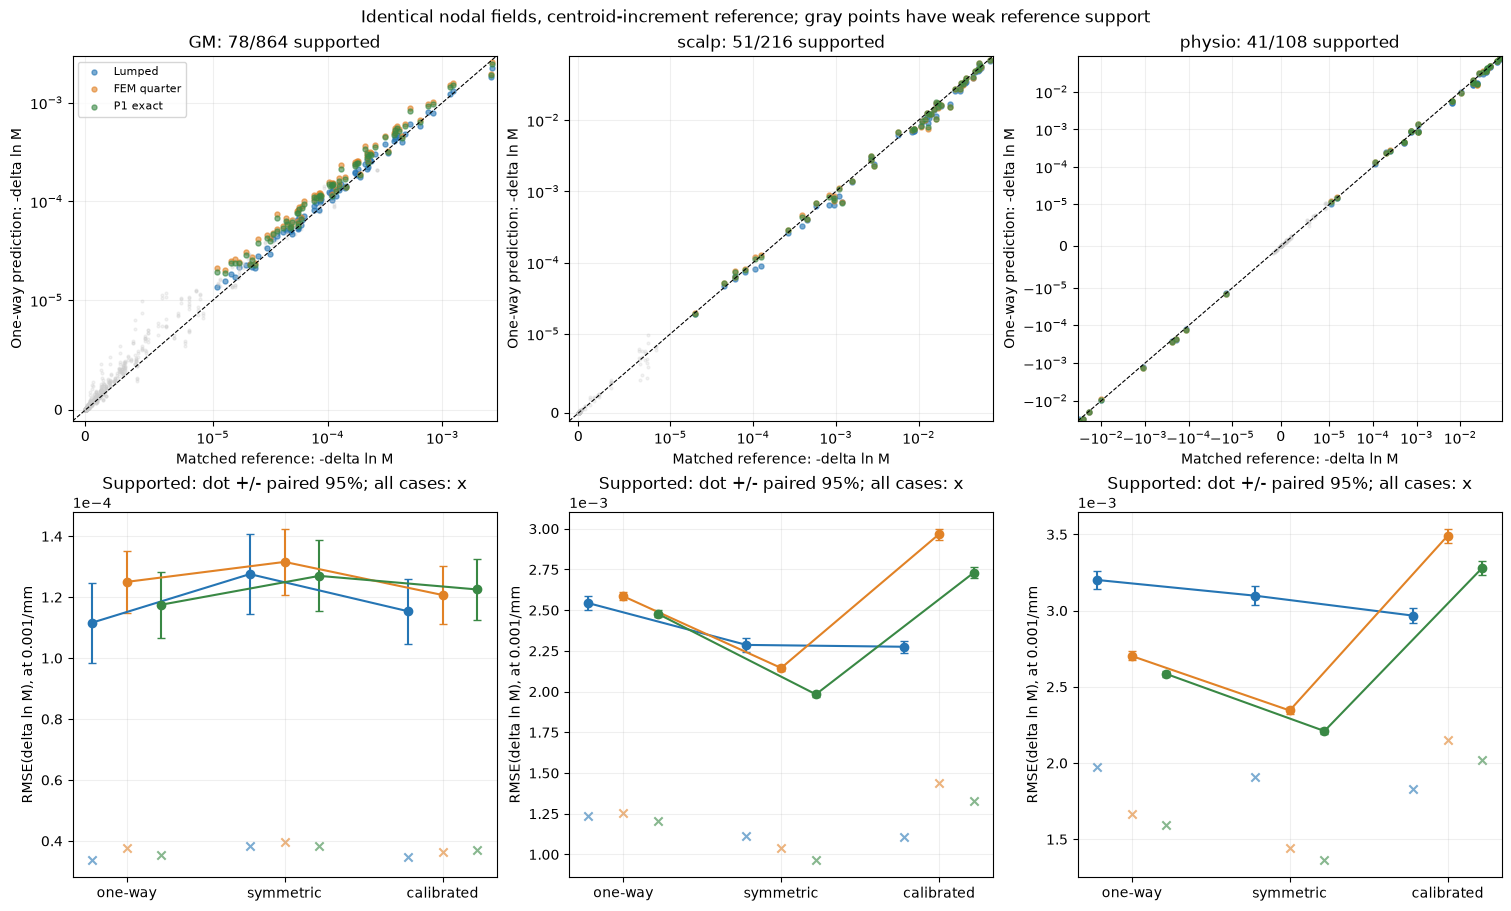

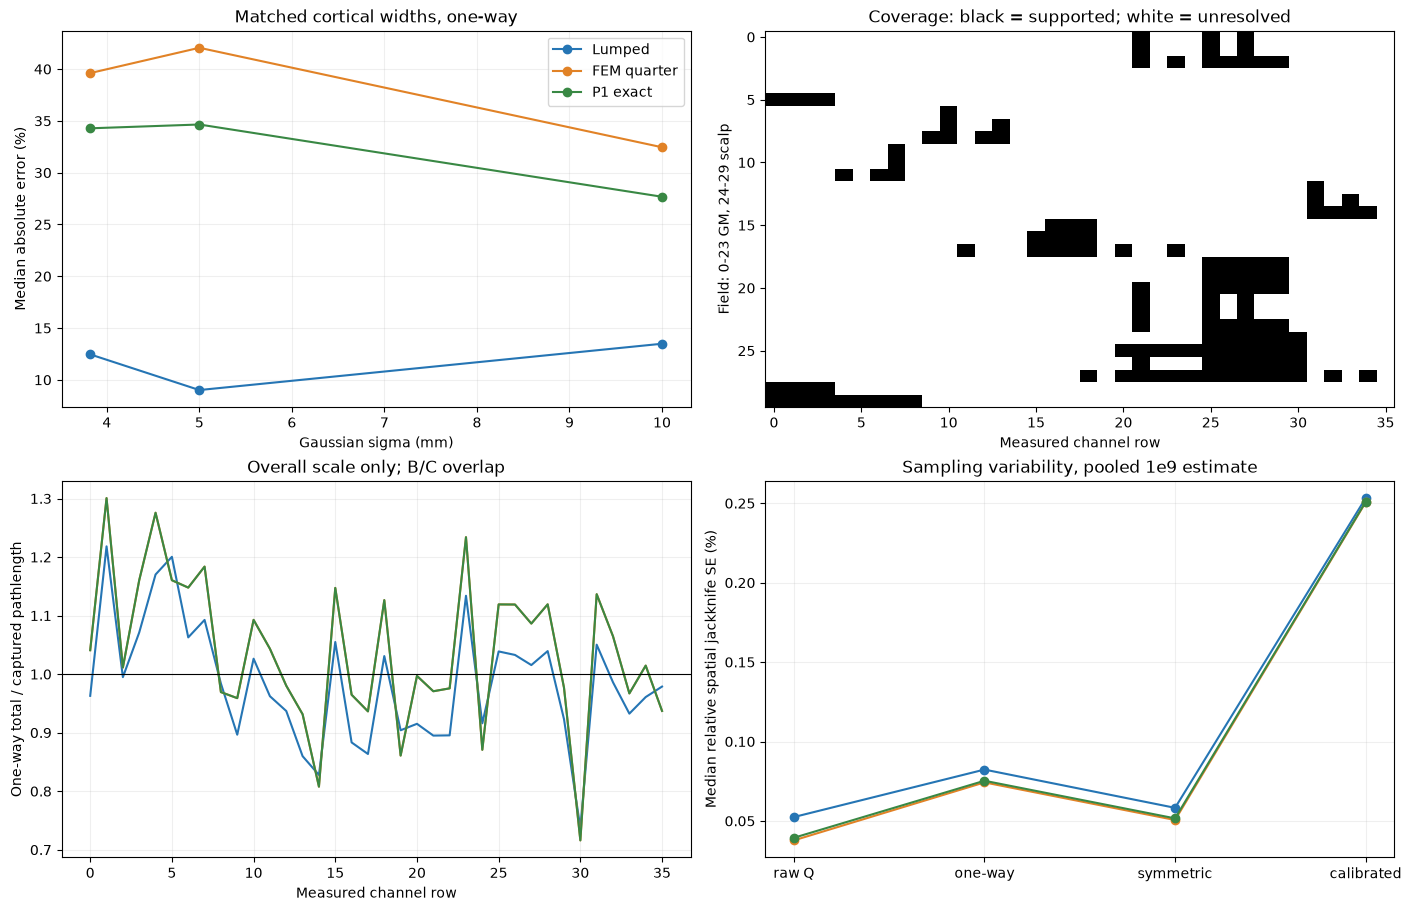

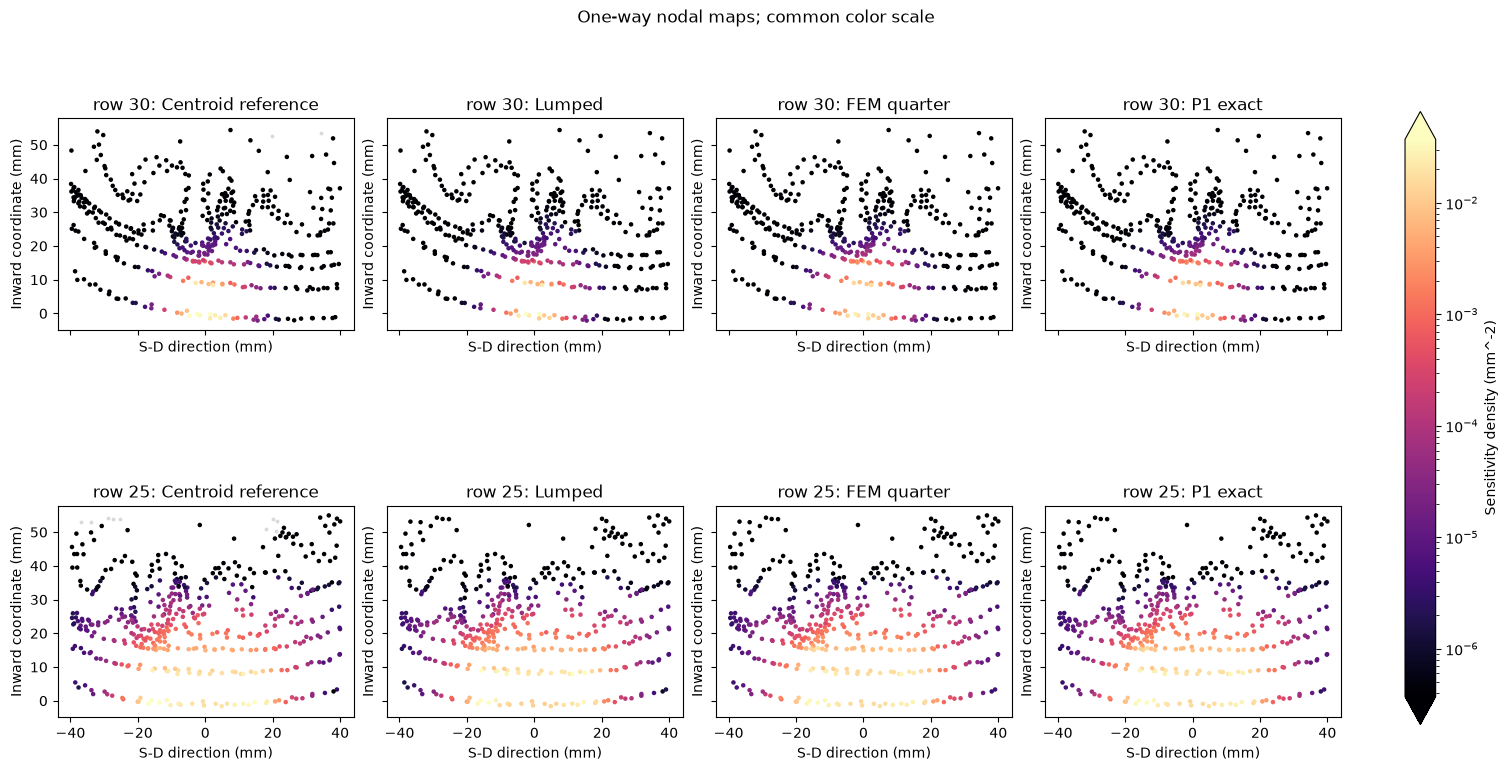

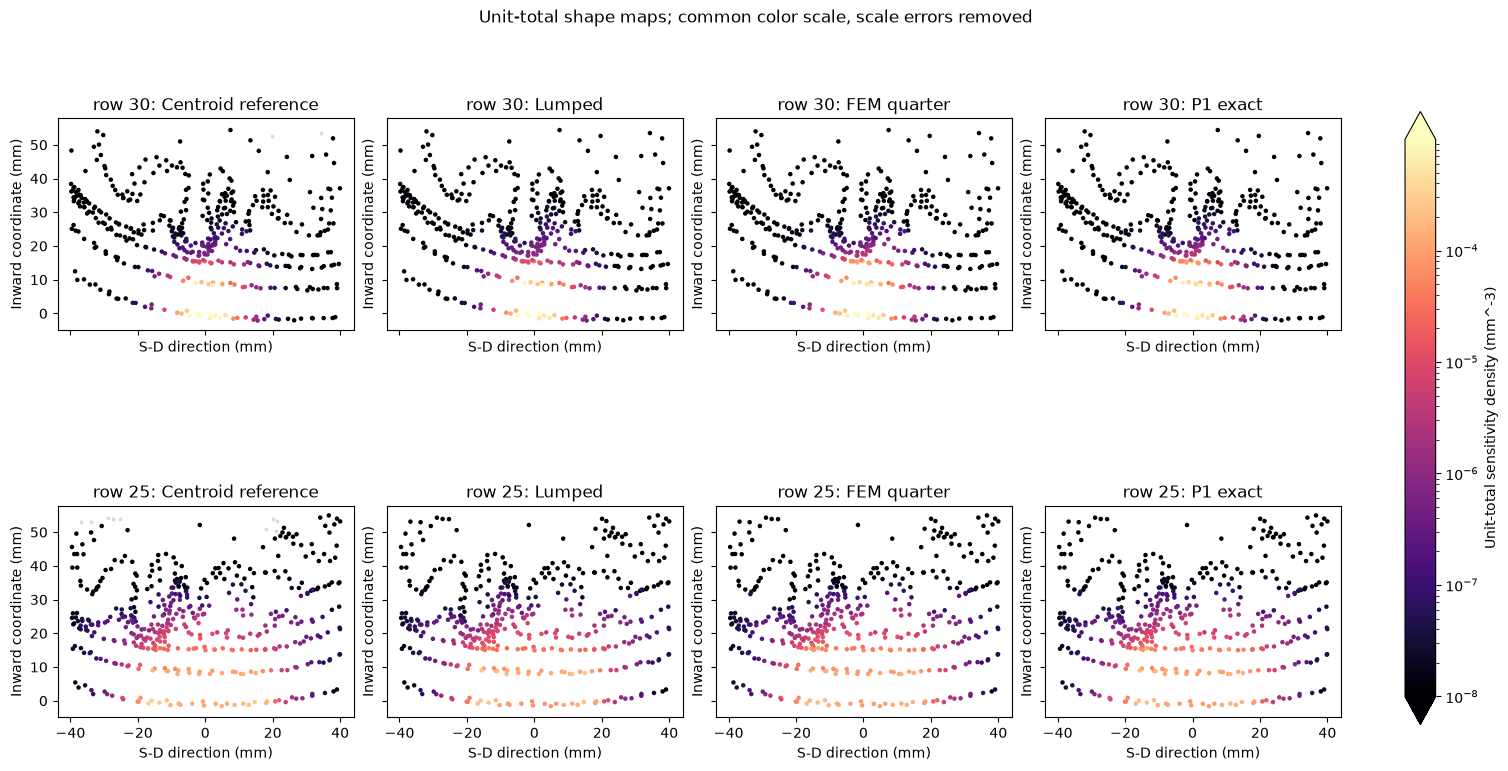

In [4]:
# 4. Response, coverage, scale, and spatial-map figures.
# Response and density views share the same measured-channel order.
from matplotlib.colors import LogNorm
colors=["#2575b4","#e18226","#398844"]
display_names=["Lumped","FEM quarter","P1 exact"]
def nmetric(m,j,group,population="supported"):
    return next(r for r in nodal_metrics if r["method"]==nodal_methods[m] and r["normalization"]==nodal_norms[j] and r["group"]==group and r["population"]==population)
nodal_scale=[]
for m,method in enumerate(nodal_methods):
    for c in range(C):
        nodal_scale.append(dict(method=method,channel=c,Q_sum_mm_inv=nqt[m,c],g_sd_mm_inv2=ng[0,c],g_ds_mm_inv2=nc["g_ds"][c],
            one_way_total_mm=-nqt[m,c]/ng[0,c],symmetric_total_mm=-nqt[m,c]/ng[1,c],captured_total_mm=nc["L_total"][c],
            beta_oneway=nbeta[m,c],one_way_total_error_pct=100*((-nqt[m,c]/ng[0,c])/nc["L_total"][c]-1)))
table("nodal_scale.csv",nodal_scale)
numerator_rows=[dict(method=method,channel=c,raw_total_mm_inv=nqt[m,c],
    total_ratio_to_lumped=nqt[m,c]/nqt[0,c],
    unit_total_shape_relative_L2_to_lumped=float(np.linalg.norm(nq[m,c]/nqt[m,c]-nq[0,c]/nqt[0,c])/np.linalg.norm(nq[0,c]/nqt[0,c])))
    for m,method in enumerate(nodal_methods) for c in range(C)]
table("nodal_numerators.csv",numerator_rows)
increment_leakage={g:float(np.sum(vol[types!=t,None]*Efields[types!=t,:][:,groups==g])/np.sum(vol[:,None]*Efields[:,groups==g]))
    for t,g in ((2,"GM"),(5,"scalp"))}
coverage=[dict(channel=c,source=int(pairs[c,0]),detector=int(pairs[c,1]),ESS=nc["ESS"][c],
    supported_GM=int(nsupported[c,groups=="GM"].sum()),supported_scalp=int(nsupported[c,groups=="scalp"].sum()),
    supported_physio=int(nsupported[c,groups=="physio"].sum()),
    largest_GM_signal_at_0p001=float(np.max(abs(nr[c,groups=="GM"]))*amplitude)) for c in range(C)]
table("nodal_coverage.csv",coverage)
width_rows=[]
for m in range(3):
    for j in range(3):
        for t,spec in enumerate(nodal_specs[:30]):
            mask=nsupported[:,t]
            width_rows.append(dict(method=nodal_methods[m],normalization=nodal_norms[j],field=spec["name"],
                group=spec["group"],sigma_mm=spec["sigma_mm"],supported_channels=int(mask.sum()),
                median_signed_error_pct=float(np.median(nerr[m,j,mask,t]/nr[mask,t])*100) if mask.any() else np.nan,
                RMSE_all_channels_lnM=float(np.sqrt(np.mean(nerr[m,j,:,t]**2))*amplitude)))
table("nodal_location_width.csv",width_rows)
# Plot absolute forward changes and paired aggregate MC uncertainty, retaining weak cases.
fig,axs=plt.subplots(2,3,figsize=(15,9),layout="constrained")
for col,group in enumerate(("GM","scalp","physio")):
    groupmask=np.broadcast_to(groups==group,nr.shape);mask=groupmask&nsupported;weak=groupmask&~nsupported
    ax=axs[0,col]
    for m in range(3):
        x=-nr*amplitude;y=-nviews[m,0]*amplitude
        ax.scatter(x[weak],y[weak],s=4,c="0.8",alpha=.25)
        ax.scatter(x[mask],y[mask],s=13,color=colors[m],alpha=.6,label=display_names[m])
    ax.errorbar((-nr*amplitude)[mask],(-nviews[0,0]*amplitude)[mask],
        xerr=nrse[mask]*amplitude,yerr=jackknife(nlooviews[0,0])[mask]*amplitude,
        fmt="none",ecolor=colors[0],alpha=.18,lw=.5)
    vals=np.r_[(-nr*amplitude)[groupmask],(-nviews[:,0]*amplitude)[:,groupmask].ravel()]
    lim=[min(0.,float(vals.min()))-1e-6,float(vals.max())*1.1]
    ax.plot(lim,lim,"k--",lw=.8)
    ax.set(xscale="symlog",yscale="symlog",xlabel="Matched reference: -delta ln M",ylabel="One-way prediction: -delta ln M",
        title=f"{group}: {mask.sum()}/{groupmask.sum()} supported",xlim=lim,ylim=lim)
    ax.set_xscale("symlog",linthresh=1e-5);ax.set_yscale("symlog",linthresh=1e-5);ax.grid(alpha=.2)
    ax=axs[1,col]
    for m in range(3):
        xx=np.arange(3)+(m-1)*.22
        rr=[nmetric(m,j,group) for j in range(3)]
        ax.errorbar(xx,[r["RMSE_lnM"] for r in rr],yerr=[2.262*r["RMSE_SE_lnM"] for r in rr],
            fmt="o-",capsize=3,color=colors[m],label=display_names[m])
        # Absolute all-case RMSE includes weak/uncoupled cases, so report it separately, not as validation.
        rrall=[nmetric(m,j,group,"all") for j in range(3)]
        ax.scatter(xx,[r["RMSE_lnM"] for r in rrall],marker="x",color=colors[m],alpha=.6)
    ax.set(xticks=np.arange(3),xticklabels=["one-way","symmetric","calibrated"],
        ylabel="RMSE(delta ln M), at 0.001/mm",title="Supported: dot +/- paired 95%; all cases: x")
    ax.ticklabel_format(axis="y",style="sci",scilimits=(0,0));ax.grid(alpha=.2)
axs[0,0].legend(fontsize=8);fig.suptitle("Identical nodal fields, centroid-increment reference; gray points have weak reference support")
fig.savefig(COMPARE/"nodal_responses.png",dpi=170);plt.show()
# Location/width, coverage and scale-versus-spatial uncertainty.
fig,axs=plt.subplots(2,2,figsize=(14,9),layout="constrained")
widths=sorted(set(s["sigma_mm"] for s in nodal_specs if s["group"]=="GM"))
for m in range(3):
    vals=[]
    for w in widths:
        mask=nsupported&np.array([s["group"]=="GM" and s["sigma_mm"]==w for s in nodal_specs])[None,:]
        vals.append(np.median(abs(nerr[m,0][mask]/nr[mask]))*100)
    axs[0,0].plot(widths,vals,"o-",color=colors[m],label=display_names[m])
axs[0,0].set(xlabel="Gaussian sigma (mm)",ylabel="Median absolute error (%)",title="Matched cortical widths, one-way");axs[0,0].legend()
im=axs[0,1].imshow(nsupported[:,:30].T,aspect="auto",interpolation="nearest",cmap="Greys",vmin=0,vmax=1)
axs[0,1].set(xlabel="Measured channel row",ylabel="Field: 0-23 GM, 24-29 scalp",title="Coverage: black = supported; white = unresolved")
for m in range(3):
    axs[1,0].plot(np.arange(C),-nqt[m]/ng[0]/nc["L_total"],color=colors[m],label=display_names[m])
axs[1,0].axhline(1,color="black",lw=.8)
axs[1,0].set(xlabel="Measured channel row",ylabel="One-way total / captured pathlength",title="Overall scale only; B/C overlap")
for m in range(3):
    axs[1,1].plot(np.arange(4),100*np.median(nc["spatial_relative_SE"][m],axis=1),"o-",color=colors[m],label=display_names[m])
axs[1,1].set(xticks=np.arange(4),xticklabels=["raw Q","one-way","symmetric","calibrated"],
    ylabel="Median relative spatial jackknife SE (%)",title="Sampling variability, pooled 1e9 estimate")
for ax in (axs[0,0],axs[1,0],axs[1,1]): ax.grid(alpha=.2)
fig.savefig(COMPARE/"nodal_coverage_scale.png",dpi=170);plt.show()
# Node response density on an oblique slab through source, detector and head interior.
# The same map scale is shared by all constructions; display density divides by volume only for visualization.
ref_nodes=np.asarray(P.T@nodal_replay["J_log_elements"].T).T
np.testing.assert_allclose(ref_nodes@Nfields,nr,rtol=1e-12,atol=1e-14)
map_channels=REFERENCE_CHANNELS
raw_maps=np.concatenate([ref_nodes[None,:,:],nq/ng[0][None,:,None]],axis=0)
shape_maps=raw_maps/raw_maps.sum(2)[:,:,None]
for mode,maps in (("absolute",-raw_maps/v),("shape",shape_maps/v)):
    selected=[];coords=[]
    for c in map_channels:
        s,d=pairs[c];center=midpoints[c]
        e1=inputs.detector_positions[d]-inputs.source_positions[s];e1/=np.linalg.norm(e1)
        e2=nodes.mean(0)-center;e2-=e1*(e1@e2);e2/=np.linalg.norm(e2);e3=np.cross(e1,e2)
        xyz=np.column_stack([(nodes-center)@e for e in (e1,e2,e3)])
        keep=(abs(xyz[:,2])<narrow_sigma)&(abs(xyz[:,0])<40)&(xyz[:,1]>-5)&(xyz[:,1]<55)
        selected.append(keep);coords.append(xyz)
    values=np.concatenate([maps[:,c,keep].ravel() for c,keep in zip(map_channels,selected)])
    vmax=float(np.percentile(values[values>0],99.7));norm=LogNorm(vmin=vmax*1e-5,vmax=vmax)
    fig,axs=plt.subplots(2,4,figsize=(15,8),layout="constrained",sharex=True,sharey=True)
    for row,(c,keep,xyz) in enumerate(zip(map_channels,selected,coords)):
        for m,title in enumerate(["Centroid reference"]+display_names):
            ax=axs[row,m];zero=keep&(maps[m,c]<=0);positive=keep&(maps[m,c]>0)
            ax.scatter(xyz[zero,0],xyz[zero,1],s=3,color=".85")
            sc=ax.scatter(xyz[positive,0],xyz[positive,1],c=maps[m,c,positive],s=5,norm=norm,cmap="magma")
            ax.set(title=f"row {c}: {title}",xlabel="S-D direction (mm)",ylabel="Inward coordinate (mm)",aspect="equal")
    fig.colorbar(sc,ax=axs.ravel().tolist(),label="Sensitivity density (mm^-2)" if mode=="absolute" else "Unit-total sensitivity density (mm^-3)",extend="both",shrink=.8)
    fig.suptitle("One-way nodal maps; common color scale" if mode=="absolute" else "Unit-total shape maps; common color scale, scale errors removed")
    fig.savefig(COMPARE/f"nodal_maps_{mode}.png",dpi=170);plt.show()


In [8]:
# 5. Element-supported comparison and 1e8-versus-1e9 sampling/roulette diagnostics.
# Element fields G and nodal fields F G have different support; this is not the nodal ranking.
def candidates(bundle):
    if "Q_nodes" in bundle:
        return {"nodal_lumped":np.asarray(F.T@bundle["Q_nodes"].T).T,"manual_FEM":bundle["Q_fem"]}
    return {"element":bundle["Q_element"]}
spatial_summary=[];spatial_convergence=[];runtime_rows=[]
H=spatial_reference["gaussian_response_mm"]
for (kind,budget),(b,m) in datasets.items():
    assert m["input_id"]==input_id
    runtime_rows.append(dict(kind=kind,budget=budget,recorded_wall_seconds=m.get("recorded_wall_seconds"),
        note="only recorded runtime; no estimate for missing values"))
    for method,q in candidates(b).items():
        for normalization,g in (("oneway",b["g_sd"]),("symmetric",(b["g_sd"]+b["g_ds"])/2),("calibrated",b["g_sd"])):
            pred=q@G/g[:,None]
            if normalization=="calibrated":
                pred*= (spatial_reference["J_log_elements"].sum(1)/(q.sum(1)/g))[:,None]
            for tissue in (2,5):
                use=supported&np.array([s["tissue"]==tissue for s in gaussian_specs])[None,:]
                err=pred[use]/H[use]-1
                spatial_summary.append(dict(budget=budget,method=method,normalization=normalization,tissue=tissue,
                    supported_channel_fields=int(use.sum()),median_abs_error_pct=float(np.median(abs(err))*100),
                    RMSE_lnM=float(np.sqrt(np.mean((pred[use]-H[use])**2))*.001),
                    reference="1e9 element replay; nodal candidate uses F G, not the same physical support"))
        if budget=="1e9":
            lower_budget=datasets[kind,"1e8"][0];lower_q=candidates(lower_budget)[method]
            for c in range(C):
                j=q[c]/b["g_sd"][c];lower_j=lower_q[c]/lower_budget["g_sd"][c]
                spatial_convergence.append(dict(method=method,channel=c,
                    raw_Q_spatial_relative_L2=float(np.linalg.norm(q[c]-lower_q[c])/np.linalg.norm(q[c])),
                    one_way_J_spatial_relative_L2=float(np.linalg.norm(j-lower_j)/np.linalg.norm(j)),
                    normalized_shape_relative_L2=float(np.linalg.norm(j/j.sum()-lower_j/lower_j.sum())/np.linalg.norm(j/j.sum())),
                    note="roulette was enabled at 1e8; not photon budget alone"))
table("spatial_summary.csv",spatial_summary);table("spatial_convergence.csv",spatial_convergence)
table("runtime.csv",runtime_rows)
# Re-evaluate the existing independent finite element-Gaussian checks, without relabeling them nodal tests.
gv=load_npz(RESULTS/"gaussian_validation_850nm.npz")
finite_reports=json.loads(str(gv["reports_json"]))
finite_summary=[]
for i,r in enumerate(finite_reports):
    derivative=float(spatial_reference["J_log_elements"][r["channel"]]@gv["quantized_fields"][:,i])
    finite_summary.append(dict(channel=r["channel"],field=r["field"],
        replay_linear_delta_lnM=derivative*r["delta_mu_mm_inv"],observed_delta_lnM=r["observed_delta_lnM"],
        paired_forward_SE=r["paired_log_SE"],same_baseline_Rytov_bias=r["linear_delta_lnM"]-r["reweighted_delta_lnM"],
        note="independent 1e8 finite check; quantized element field, not continuous P1 or the new nodal fields"))
table("finite_validation.csv",finite_summary)
print("Element-reference, finite-perturbation and 1e8/1e9 comparisons reproduced.")


Element-reference, finite-perturbation and 1e8/1e9 comparisons reproduced.


In [6]:
# Three-seed 1e8 dataset: sampling uncertainty and native own-field formula checks.
rep=load_npz(RESULTS/"audited_pair_850nm_1e8_repeats.npz")
repmeta=metadata(rep);assert repmeta["input_id"]==input_id
diagnostics=[]
repeat_rows=[]
def variation(method,category,a,gains):
    total=a.sum(1);mean=a.mean(0)
    return dict(method=method,category=category,seeds="164833,271831,314159",
        total_CV_pct=100*total.std(ddof=1)/abs(total.mean()),
        spatial_RMS_relative_L2_pct=100*np.sqrt(np.mean(np.sum((a-mean)**2,axis=1)))/np.linalg.norm(mean),
        motor_CV_pct=100*gains[:,0].std(ddof=1)/abs(gains[:,0].mean()),
        scalp_CV_pct=100*gains[:,4].std(ddof=1)/abs(gains[:,4].mean()))
for method,key,gkey,absorption in (("nodal_lumped","Q_nodes","nodal_g_sd",Bn),
                                  ("manual_FEM","Q_fem","nodal_g_sd",B),
                                  ("element","Q_element","element_g_sd",B)):
    q=rep[key];j=q/rep[gkey][:,None]
    repeat_rows.append(variation(method,"raw bilinear Q, mm^-1",q,q@absorption))
    repeat_rows.append(variation(method,"uncalibrated point-converted J, mm",j,j@absorption))
    beta=rep["nodal_L_tissue"].sum(1)/(-j.sum(1))
    repeat_rows.append(variation(method,"downstream calibrated diagnostic, mm",j*beta[:,None],(j@absorption)*beta[:,None]))
    repeat_rows[-1]["beta_CV_pct"]=100*beta.std(ddof=1)/beta.mean()
L=rep["nodal_L_tissue"]
repeat_rows.append(dict(method="captured_history",category="captured-history reference variability",
    total_CV_pct=100*L.sum(1).std(ddof=1)/L.sum(1).mean(),
    gray_matter_CV_pct=100*L[:,1].std(ddof=1)/L[:,1].mean(),
    scalp_CV_pct=100*L[:,4].std(ddof=1)/L[:,4].mean(),
    note="cortical region/spatial reference unavailable; roulette boosts not recorded"))
repeat_rows.append(variation("native_jmua","raw native nodes, mm^-1; tissue allocation from own FEM cells",
                            rep["native_jmua"],rep["native_Q_fem"]@B))
for i,seed in enumerate(rep["seeds"]):
    q,j=rep["native_Q_fem"][i],rep["native_jmua"][i]
    residual=np.linalg.norm(P.T@q-j)/np.linalg.norm(j);assert residual<3e-4
    manual=rep["Q_fem"][i]
    diagnostics.append(dict(kind="cached_native",seed=int(seed),raw_jmua_sum_mm_inv=j.sum(),
        own_field_FEM_relative_L2=residual,
        native_manual_normalized_shape_L2=np.linalg.norm(q/q.sum()-manual/manual.sum())/np.linalg.norm(manual/manual.sum()),
        source_unit_field_relative_L2=rep["native_unit_field_relative_L2"][i],
        note="recorded-normalizer diagnostic, no fitted scalar; absolute captured-log conversion unvalidated"))
table("repeat_variability.csv",repeat_rows);table("diagnostics.csv",diagnostics)
# Localized Gaussian variability from the same three saved 1e8 seeds.
repeat_spatial=[]
for method,key,gkey in (("nodal_lumped","Q_nodes","nodal_g_sd"),("manual_FEM","Q_fem","nodal_g_sd"),("element","Q_element","element_g_sd")):
    q=rep[key]
    if method=="nodal_lumped": q=np.asarray(F.T@q.T).T
    raw_gains=q@G;point_gains=raw_gains/rep[gkey][:,None]
    factors=rep["nodal_L_tissue"].sum(1)/(-q.sum(1)/rep[gkey])
    for category,a in (("raw_Q",raw_gains),("uncalibrated_J",point_gains),("downstream_calibrated",point_gains*factors[:,None])):
        for i,g in enumerate(gaussian_specs):
            repeat_spatial.append(dict(method=method,category=category,field=g["name"],
                mean=float(a[:,i].mean()),CV_pct=float(100*a[:,i].std(ddof=1)/max(abs(a[:,i].mean()),1e-300)),
                note="pair (5,9), three 1e8 seeds; no spatial path reference in this dataset"))
table("repeat_spatial_variability.csv",repeat_spatial)


In [10]:
# 6. Compact decision record and final invariants.
assert np.isfinite(nq).all() and np.all(nq<=0)
assert np.all(nc["N_source"]==1_000_000_000)
for group,expected in (("GM",78),("scalp",51),("physio",41)):
    assert int(nsupported[:,groups==group].sum())==expected
for m,expected in enumerate((12.4646,37.4028,32.3883)):
    assert abs(nmetric(m,0,"GM")["median_abs_relative_pct"]-expected)<.05
no_gm=np.flatnonzero(nsupported[:,groups=="GM"].sum(1)==0).tolist()
lines=[
"MMC v2026 / Colin27 — final nodal selection (offline reference)",
"",
"Current integration choice: retain geometric nodal lumping with one-way normalization.",
"This working choice is not an overall metric winner or a claim of exact physical validation.",
"Calibration remains optional and disabled.",
"J[c,i] = -v[i]*Gs[i]*Gd[i]/g_sd[c], in mm. Volume is already included.",
"Absorption: centroid-averaged nodal increments on an unchanged heterogeneous tissue baseline.",
"Measurement: captured exit energy at the original radius-1-mm detector spheres, 0–5 ns, no NA.",
"This fluence product with an embedded inward pencil is an approximate captured-log estimator, not a matched RTE adjoint.",
"",
"Scientific tradeoff: lumping gives the best raw cortical RMSE and typical cortical-location error.",
"Population: only the 36 measured/selected pairs, not all 216 all-pair combinations. Headline metrics use supported channel-field cases.",
"P1/symmetric improves scalp/systemic RMSE. No method achieves uniform 10% accuracy and no universal optimum is claimed.",
"More exact quadrature does not establish more accurate transport sensitivity.",
"",
"Error definition: E[c,f] = 0.001 * ((J_candidate - J_element_weighted_pathlength @ P) @ b_f)[c].",
"The reference estimates the configured MMC captured-energy derivative for centroid-nodal increments, not experimental head/detector truth.",
"RMSE is over log-response discrepancies; median percentage is relative to each supported non-negligible reference response.",
"Replay has finite sampling uncertainty and shares baseline histories; paired chunk analysis includes this covariance.",
"Small absolute values scale with the test amplitude and do not establish small physical-model errors.",
"",
"Supported cases; RMSE of delta ln M at nodal amplitude 0.001/mm, followed by median absolute relative error:",
"method / normalization             GM                 scalp              physiology"]
for m,method in enumerate(nodal_methods):
    for j,norm in enumerate(nodal_norms):
        metrics=[nmetric(m,j,g) for g in ("GM","scalp","physio")]
        lines.append(f"{method:12s}/{norm:10s}  "+"  ".join(f"{r['RMSE_lnM']:.6g} [{r['median_abs_relative_pct']:.2f}%]" for r in metrics))
lines += [
"",
"Raw Q, point-normalized J, reference uncertainty and calibration variability are reported separately.",
"One-way/symmetric denominators change row scale only; calibrated versions cancel exactly for a fixed numerator.",
f"Median absolute symmetric row-scale change: {100*np.median(abs(row_multiplier-1)):.2f}%; multiplier range {row_multiplier.min():.3f} to {row_multiplier.max():.3f}.",
"With lumping, symmetric raises cortical RMSE 14.3% (absolute 1.60e-5 ln M), but lowers scalp/physiology RMSE 10.1%/3.2%.",
"Median cortical percentage error improves from 12.46% to 11.19% with symmetric. Strong responses dominate RMSE.",
f"Paired normalization effects, symmetric minus one-way: {[r for r in normalization_effects if r['method']=='lumped']}",
"These differences exceed MC uncertainty but do not establish general practical or physical superiority. No instrument-noise threshold was supplied.",
"Keep one-way for integration; symmetric and Sassaroli remain diagnostics. Calibration improves several lumped metrics, without proving the detector approximation.",
"Sassaroli cannot repair spatial mismatch. Never fit separate tissues or perturbation outcomes.",
f"Supported GM/scalp/physio cases: 78/864, 51/216, 41/108. No supported GM test for rows {no_gm}.",
f"Median spatial SE (%), raw Q / one-way / symmetric / calibrated: {np.round(100*np.median(nc['spatial_relative_SE'],axis=2),3).tolist()} for lumped / quarter / P1.",
"Ten paired delete-one chunks describe one pooled 1e9 run, preserving shared-field/reference covariance.",
"All-case absolute errors remain visible; weak or zero replay signals are not established insensitivity.",
"",
f"Native own-field quarter reconstruction residual: {model_checks['native_own_field_max_relative_L2']:.3g}. Raw jmua stays in its original units.",
f"Quarter/P1 total relative discrepancy: {model_checks['B_C_total_max_relative_difference']:.3g}. Both are numerical consistency checks.",
f"Replacing baseline by PF mu0 would alter {100*model_checks['baseline_changed_element_fraction']:.2f}% of elements; it was not done.",
f"GM/scalp nodal Gaussian volume leaking into other tissues after P: {100*increment_leakage['GM']:.1f}% / {100*increment_leakage['scalp']:.1f}%. This is absorption-model smoothing.",
"Je_replay P is the centroid-increment reference, not a continuous-P1 pathlength derivative.",
"Element-replay finite tests use quantized element Gaussians and do not establish arbitrary nodal finite-amplitude validity.",
"",
"Downstream: J theta = delta ln M; natural OD = -J theta; decadic OD = -J theta/ln(10).",
"Audit shapes: Q=(3,36,58686), J per view=(36,58686). Production all-pair J=(216,58686), mea0=(216,1).",
"Use explicit pairs and channel_indices; audit bundles are not production-format drop-ins.",
"Minimal integration: retain the current assembly, units and nodal projection; document the increment model and approximation.",
"All three end-to-end workflows call the unchanged nodal one-way generator. No Sassaroli scaling is applied; pathlength_ratio is diagnostic only.",
"No scientific production formula was changed. Workflow runtime selection refreshes the manifest and makes CUDA optional.",
"",
f"Recorded nodal field campaign: {datasets['nodal','1e9'][1]['recorded_wall_seconds']/60:.1f} min.",
f"Recorded assembly seconds lumped / quarter / P1: {np.round(nmeta['assembly_seconds'],3).tolist()}.",
"Mean fields reproduce all three numerators. Fixed-test jackknife projections and the three-seed results remain saved.",
"Raw trajectories/chunk fields were removed during cleanup; new arbitrary-field replay uncertainty requires regeneration.",
"All cells are offline; there are no transport launchers or execution switches to enable."]
(COMPARE/"nodal_decision.txt").write_text("\n".join(lines)+"\n")
save_json(COMPARE/"offline_validation.json",dict(numerators_reconstructed=True,channel_ids_verified=True,
    analytical_tests_passed=True,raw_cache_required=False,Q_shape=nq.shape,
    retained_npz_sha256={p.name:sha(p) for p in RESULTS.glob("*.npz")}))
print("Offline validation passed. Recommendation: lumped / one-way; optional calibration OFF.")
print("Report:",COMPARE/"nodal_decision.txt")

Offline validation passed. Recommendation: lumped / one-way; optional calibration OFF.
Report: /home/nbracher/Documents/Projects/mmc-nirs/notebooks/jacobian_audit/comparison/nodal_decision.txt


**Integration setting: nodal lumping with one-way normalization; calibration off.** The end-to-end workflows already use this equation, so no scientific production change is needed.

The comparisons quantify discrepancies against a noisy captured-pathlength reference for the declared MMC model. They do not establish experimental accuracy. Normalization changes channel scale; spatial allocation and detector/absorption modeling remain separate uncertainties.

Headline metrics use supported channel–field cases among the **36 measured channels**. All-case tables retain every measured row; the other 180 possible pairs are excluded. Keep raw and calibrated results distinct, preserve explicit channel identities, and do not multiply integrated J by volume again.
